rumz
# Notebook for processing layers in ice
### May 25
#### V. 2.1
- Updated with better bubble detection and inpainting
- Uses Median and Mean, not just Sum


This notebook processes hyperspectral images of ice and extracts information in regards to climate proxies.
To run:
- ensure datasetPath points to the correct directory file
- Insert DataID for whichever core to be run

In [1]:
import warnings
import sys
import os
import datetime
import matplotlib.pyplot as plt

# Add the processing folder to the Python path
processing_path = os.path.abspath(os.path.join('..', 'processing'))
if processing_path not in sys.path:
    sys.path.append(processing_path)

#Importing Python Libraries and Packages
import pandas as pd
import numpy as np
import set_icespec_path as tool
import set_bubbles_path as tool2
icespec_code_path=tool.add_icespec_code_dir()
bubble_code_path=tool2.add_bubble_code_dir()
tool.add_icespec_code_dir()
tool2.add_bubble_code_dir()
from icespec import icespec_process2_module as processice
from bubbles import bubbles_process_module as processbubbles
from Sums import sums_process_module as processSums
from icespec import savePNG
from icespec import ageConversion

### Users should fill in variables with desired core info
Use HSI_July2024 Spreadsheet for ID and section names

Debug variable prints more information during processing

In [2]:
DataID = "HSIUM-17" #insert DataID from excel file inside quotation marks

## This should be its own function ##
NumID = int(DataID.split('-')[-1])
if NumID <= 228:
    datasetPath = '/data/icecores/HSI_2024.csv'
elif 229 <= NumID < 335:
    datasetPath = '/data/icecores/HSI_2023_1.csv'
elif 335 <= NumID < 363:
    datasetPath = '/data/icecores/HSI_June2025.csv'
elif 363 <= NumID < 586:
    datasetPath = '/data/icecores/HSI_Sept2025.csv'
elif 586 <= NumID < 751:
    datasetPath = '/data/icecores/HSI_Denali2025.csv'
elif 751 <= NumID < 873:
    datasetPath = '/data/icecores/HSI_Jan2024.csv'
else:
    raise ValueError(f"NumID {NumID} is outside supported ranges (<=228, 229–334, 335–362, 363–585, 586–750, 751–872). \n Please check DataID and try again.")
    

outputDir = '/data/icecores/Output' #png output path
SCRIPT_ID = "LayersNB"

Debug = True
Save = True

In [3]:
dataPath, top_depth, bottom_depth, core_length, save_path, px_dims, metadata = processice.getDataPath(datasetPath, DataID, outputDir)

outputPath = processice.make_dir(save_path, SCRIPT_ID, metadata)
print("Output Path: ", outputPath)

data_nparr, w_ref, d_ref, wvls, fwhm = processice.getEnviData(dataPath)

Core:  ALHIC 2302
Section:  42 Sec 50
Lighting: Top light - 100%, Bottom Light - 0%
Exposure:  16
Top Depth:  37.8
Bottom Depth:  38.84
Length =  1.0400000000000063
Dimensions:  1400, 7450, 200, 850
Data Path:  July2024/ALHIC2302-42_0001_HSI_UM_Jul24
Output Path:  /data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-42/2026-03-27_152919
<class 'numpy.ndarray'>


In [4]:
segment_boundaries, px_per_cm = processbubbles.get_segments(data_nparr, top_depth, bottom_depth, end_px=px_dims[1])
print("pixels per cm: ", px_per_cm)

core bottom depth: 38.84 - core top depth: 37.8 = core length: 1.0400000000000063
core length cm: 104.00000000000063
end px: 7450 - start px: 1200 = total px height: 6250
ice height px: 6250 / core length cm: 104.00000000000063 = px per cm: 60.096153846153484
standard px height: 325 / standard length: 5.08 = px per cm: 63.976377952755904
pixels per cm:  63.976377952755904


In [5]:
#dataSize = [1500, 6600, 200, 900] #fill in based on interactive plot
dataSize = [2000, 3000, 200, 400]
stdSize = [530, 820, 200, 900] #standard sizing

The new dimensions will be: 650x6050
Trimmed shapes: (6050, 650, 224), W_ref: (175, 650, 224), D_ref: (100, 650, 224)


/home/rumz/anaconda3/envs/HSenv/lib/python3.12/site-packages/spectral/graphics/spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)


Reflectance calculated. Dimensions: (6050, 650, 224)


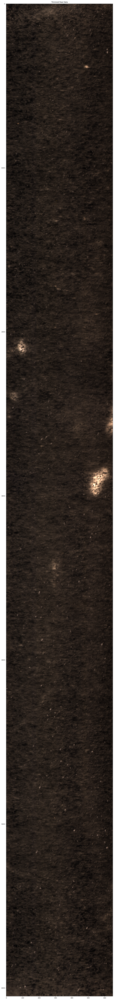

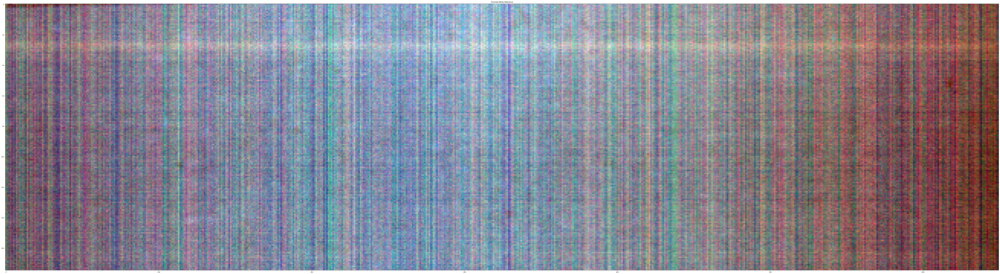

In [6]:
trimmedData = processice.trim(data_nparr, w_ref, d_ref, px_dims, stdSize, Debug=Debug) #return arr of 3 trimmed
correctedData = processice.reflectance(trimmedData, Debug)

In [7]:
# filtered_img, wvls, fwhm = processice.remove_bands(correctedData, trimmedData[1], wvls, fwhm, Debug=True, outputPath=outputPath, save=True)
# filename = f"{DataID}filtered.png"
# rgb_slice = filtered_img[:, :, [34, 21, 13]].astype(np.float32)
# rgb_norm = (rgb_slice - rgb_slice.min()) / (rgb_slice.max() - rgb_slice.min())
# plt.imsave(f"{outputPath}/{filename}", rgb_norm, dpi=600)
# readme_path = outputPath / "README.md"
# with readme_path.open("a") as f:
#     f.write(f"\n###  Output File: {filename}\n- {DataID}: Image of Filtered Data post Ref Correction\n")

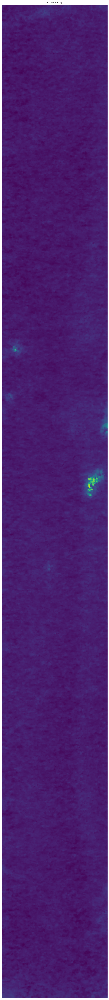

In [8]:
inpainted_img = processice.bubbles(correctedData,  fwhm)

In [9]:
# import copy 
# inpaint_copy = copy.deepcopy(inpainted_img)

# pc_image = processice.pc_infill(inpaint_copy, num_pcs=5, fill_mode="tile")

In [10]:
# sums_img, full_img_sums = processSums.channel_sums(pc_image, px_per_cm, top_depth, Debug, Save, outputPath, True)
# combined_df, per_section = processSums.sum_comparison(pc_image, px_per_cm, top_depth, Debug, Save, outputPath, True)

Row 0: sum=1.452e+05, median=1.007, mean=0.997
Row 1: sum=1.465e+05, median=1.013, mean=1.006
Row 2: sum=1.445e+05, median=0.998, mean=0.9924
Row 3: sum=1.446e+05, median=0.997, mean=0.9934
Row 4: sum=1.445e+05, median=0.9942, mean=0.9926


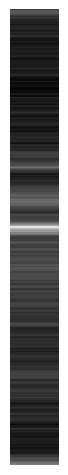

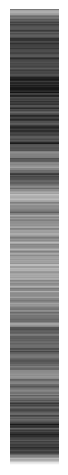

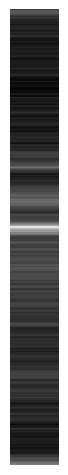

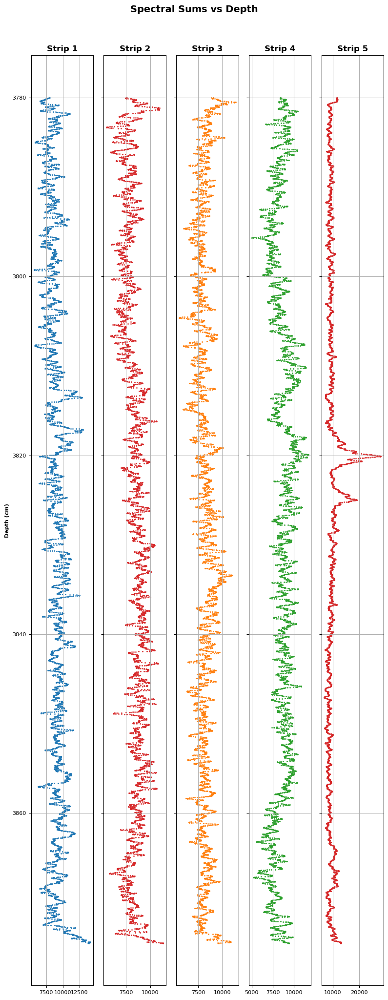

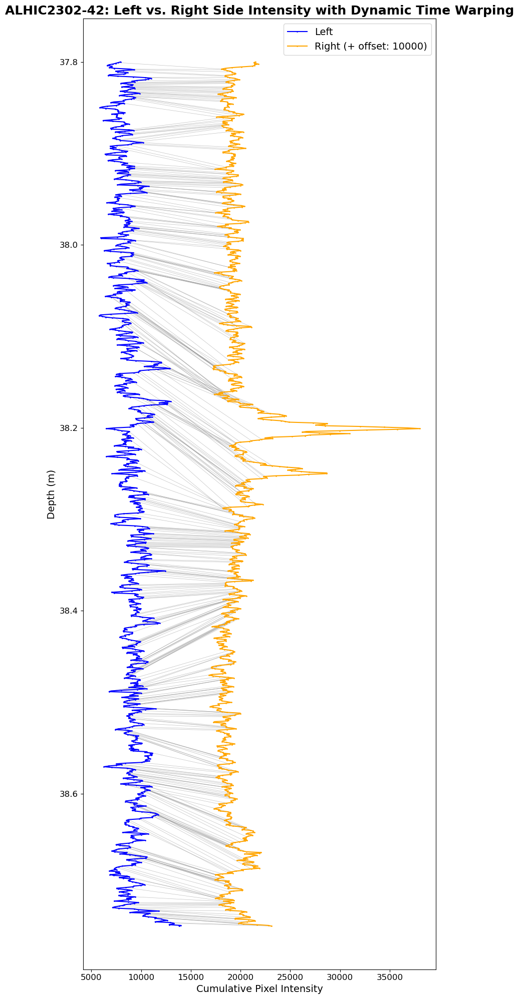

In [11]:
sums_img, full_img_sums = processSums.channel_sums(inpainted_img, px_per_cm, top_depth, Debug, Save, outputPath)
combined_df, per_section = processSums.sum_comparison(inpainted_img, px_per_cm, top_depth, Debug, True, outputPath)

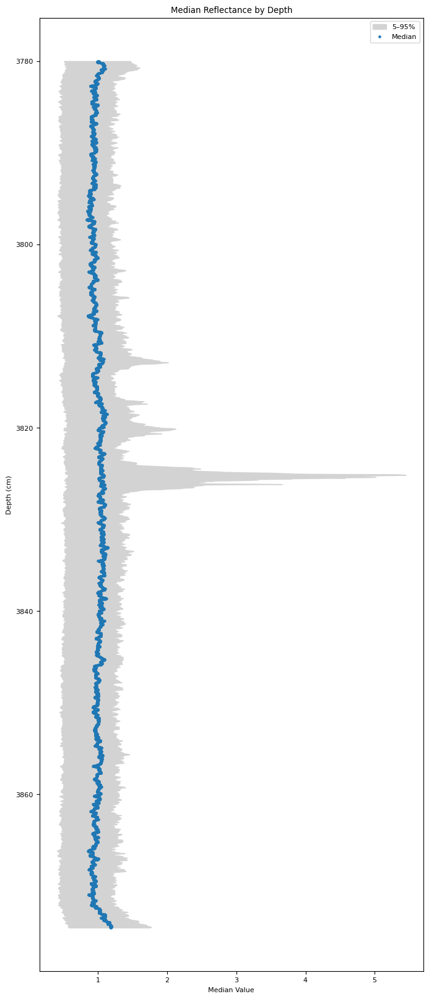

In [12]:
import matplotlib.pyplot as plt

# Sort by depth just in case
full_img_sums = full_img_sums.sort_values("Depth_cm")

plt.figure(figsize=(8, 20))

# 5–95% shaded band
plt.fill_betweenx(
    full_img_sums["Depth_cm"],
    full_img_sums["Median_5"],
    full_img_sums["Median_95"],
    color="lightgray",
    label="5–95%"
)

# Median line
plt.scatter(
    full_img_sums["Medians"],
    full_img_sums["Depth_cm"],
    s=5,          # point size
    label="Median"
)

plt.gca().invert_yaxis()  # depth increases downward
plt.xlabel("Median Value")
plt.ylabel("Depth (cm)")
plt.title("Median Reflectance by Depth")
plt.legend()

plt.show()

In [13]:
# import matplotlib.pyplot as plt

# sections = sorted(combined_df["Section"].unique())

# s1 = combined_df[combined_df["Section"] == 1]
# s2 = combined_df[combined_df["Section"] == 2]
# s3 = combined_df[combined_df["Section"] == 3]
# s4 = combined_df[combined_df["Section"] == 4]
# s5 = combined_df[combined_df["Section"] == 5]

# s1 = s1.sort_values(by='Depth_cm')
# s2 = s2.sort_values(by='Depth_cm')
# s3 = s3.sort_values(by='Depth_cm')
# s4 = s4.sort_values(by='Depth_cm')
# s5 = s5.sort_values(by='Depth_cm')

# s1 = s1['Sums'].values[0::5]
# s2 = s2['Sums'].values[0::5]
# s3 = s3['Sums'].values[0::5]
# s4 = s4['Sums'].values[0::5]
# s5 = s5['Sums'].values[0::5]

# s1 = np.nan_to_num(s1)
# s2 = np.nan_to_num(s2)
# s3 = np.nan_to_num(s3)
# s4 = np.nan_to_num(s4)
# s5 = np.nan_to_num(s5)

# print(s1)

In [14]:
# from dtaidistance import dtw, dtw_visualisation as dtwvis
# from scipy.interpolate import interp1d
# from scipy.stats import pearsonr

# distance, paths = dtw.warping_paths(s1, s5)
# best_path = dtw.best_path(paths)
# similarity_score = distance / len(best_path)

# # distance1, paths1 = dtw.warping_paths(s2, s3)
# # best_path1 = dtw.best_path(paths1)
# # similarity_score1 = distance1 / len(best_path1)

# # distance2, paths2 = dtw.warping_paths(s3, s4)
# # best_path2 = dtw.best_path(paths2)
# # similarity_score2 = distance2 / len(best_path2)

# # distance3, paths3 = dtw.warping_paths(s3, s5)
# # best_path3 = dtw.best_path(paths3)
# # similarity_score3 = distance3 / len(best_path3)

In [15]:
# plt.figure(figsize=(12, 8))

# # Original Time Series Plot
# ax1 = plt.subplot2grid((2, 2), (0, 0))
# ax1.plot(s1, label='Series 1', color='blue')
# ax1.plot(s5, label='Series 2', linestyle='--',color='orange')
# ax1.set_title('Original Time Series')
# ax1.legend()

# # Shortest Path Plot (Cost Matrix with the path)
# # In this example, only the path is plotted, not the entire cost matrix.

# ax2 = plt.subplot2grid((2, 2), (0, 1))
# ax2.plot(np.array(best_path)[:, 0], np.array(best_path)[:, 1], 'green', marker='o', linestyle='-')
# ax2.set_title('Shortest Path (Best Path)')
# ax2.set_xlabel('Series 1')
# ax2.set_ylabel('Series 2')
# ax2.grid(True)

# # Point-to-Point Comparison Plot
# ax3 = plt.subplot2grid((2, 2), (1, 0), colspan=2)
# ax3.plot(s1, label='Series 1', color='blue', marker='o')
# ax3.plot(s5+12000, label='Series 2 + offset', color='orange', marker='x', linestyle='--')
# for a, b in best_path:
#     ax3.plot([a, b], [s1[a], s5[b]], color='grey', linestyle='-', linewidth=1, alpha = 0.5)
# ax3.set_title('Point-to-Point Comparison After DTW Alignment')
# ax3.legend()

# plt.tight_layout()
# plt.show()

In [16]:
# import matplotlib.pyplot as plt

# offset = 12000  # vertical spacing between the series
# s2_offset = s5 + offset
# # s3_offset = s5 + (offset * 2)
# # s4_offset = s4 + (offset * 3)
# # s5_offset = s5 + (offset * 4)
# combined_df = combined_df.sort_values(by='Depth_cm')
# combined_df['Depth_cm'] = combined_df['Depth_cm'] / 100
# depths = combined_df["Depth_cm"].values[0::5]  # assumes same for both series

# # Flip so Depth is y-axis
# plt.figure(figsize=(8, 20))

# # Draw alignment lines
# for a, b in best_path:
#     plt.plot([s1[a], s2_offset[b]], [depths[a], depths[b]], color='gray', alpha=0.5, linewidth=0.5)
# # for a, b in best_path3:
# #     plt.plot([s2_offset[a], s3_offset[b]], [depths[a], depths[b]], color='gray', alpha=0.5, linewidth=0.5)
# # for a, b in best_path2:
# #     plt.plot([s3_offset[a], s4_offset[b]], [depths[a], depths[b]], color='gray', alpha=0.5, linewidth=0.5)
# # for a, b in best_path3:
# #     plt.plot([s4_offset[a], s5_offset[b]], [depths[a], depths[b]], color='gray', alpha=0.5, linewidth=0.5)

# # Plot Series
# plt.plot(s1, depths, label='Left', color='blue', marker='.', markersize=2)
# plt.plot(s2_offset, depths, label='Middle', color='orange', marker='x', linestyle='--', markersize=2)
# # plt.plot(s3_offset, depths, label='Right', color='green', marker='.', markersize=2)
# # plt.plot(s4_offset, depths, label='Strip 4 + offset', color='red', marker='x', linestyle='--', markersize=2)
# # plt.plot(s5_offset, depths, label='Strip 5 + offset', color='purple', marker='.', markersize=2)

# plt.gca().invert_yaxis()  # Depth increases downward

# plt.ylabel('Depth (m)')
# plt.title('ALHIC2302-29 Layers with DTW')
# plt.legend()
# plt.tight_layout()
# plt.savefig(f"{outputPath}/DTW.png", dpi=300, bbox_inches='tight')
# plt.show()

In [17]:
# offset = 3

# plt.figure(figsize=(7,12))

# for i, section in enumerate(sections):
#     sub = combined_df[combined_df["Section"] == section]

#     x_vals = sub["Medians"] + i * offset     # apply offset per section
#     y_vals = sub["Depth_cm"]

#     plt.plot(x_vals, y_vals, label=f"Section {section}")

# plt.gca().invert_yaxis() 
# plt.xlabel("Median (offset by 600 per section)")
# plt.ylabel("Depth (cm)")
# plt.legend()
# plt.tight_layout()
# plt.show()

In [18]:
# from fastdtw import fastdtw
# from scipy.spatial.distance import euclidean

# sections = sorted(df["Section"].unique())

# # Build dictionary: section -> 1D list of medians (in depth order)
# series = {}
# for s in sections:
#     sub = df[df["Section"] == s].sort_values("Depth_cm")
#     series[s] = sub["Medians"].to_list()

# # Compute DTW between each pair
# dtw_results = {}

# for i, s1 in enumerate(sections):
#     for s2 in sections[i+1:]:
#         distance, path = fastdtw(series[s1], series[s2], dist=euclidean)
#         dtw_results[(s1, s2)] = distance


# sA, sB = 0, 1
# seqA = series[sA]
# seqB = series[sB]

# distance, path = fastdtw(seqA, seqB, dist=euclidean)

# # Plot the warping path
# plt.figure(figsize=(6,6))
# plt.plot([p[0] for p in path], [p[1] for p in path])
# plt.xlabel(f"Index in Section {sA}")
# plt.ylabel(f"Index in Section {sB}")
# plt.title(f"DTW Warping Path (distance={distance:.1f})")
# plt.show()


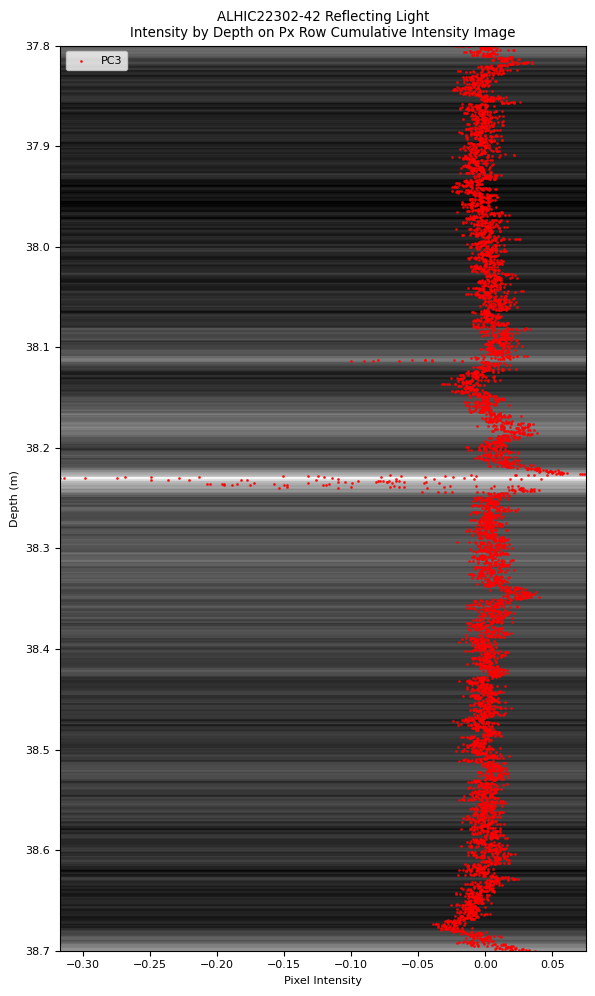

In [33]:
import matplotlib.image as mpimg
from pathlib import Path

imgPath = "/data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-42/2026-03-09_121205"
pcaPath = "/data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-42/HSIUM-17-2026-03-25_141857"

csv_name = "HSIUM-17pca_by_depth.csv"
img_name = "row_sums.png"
x_col= "PC1"
y_col= "Depth_cm"
pc2_col= "PC2"
pc3_col= "PC3"

csv_path = Path(str(pcaPath + "/" + csv_name))
img_path = Path(str(imgPath + "/" + img_name))

# --- Load data ---
df = pd.read_csv(csv_path).dropna(subset=[y_col, pc3_col])
df['Depth_cm'] = df['Depth_cm'].values / 100
img = mpimg.imread(img_path)
H, W = img.shape[0], img.shape[1]

# print(f"Image Shape: {img.shape}")
# print(f"CSV Shape: {df.shape}")

# --- Map data -> pixel space of the image ---
x_min, x_max = float(df[pc3_col].min()), float(df[pc3_col].max())
y_min, y_max = float(df[y_col].min()), float(df[y_col].max())

def linmap(v, a0, a1, b0, b1):
    return b0 + (np.asarray(v) - a0) * (b1 - b0) / (a1 - a0 + 1e-12)

x_px = df[pc3_col]
y_px = linmap(df[y_col], y_min, y_max, 0, H)


# --- Plot ---
fig, ax = plt.subplots(figsize=(6, 10))
ax.imshow(img, extent=[x_min, x_max, H, 0], aspect="auto", interpolation="nearest", zorder=1)

ax.scatter(x_px, y_px, s=1, c="red", alpha=0.8, zorder=2, label="PC3")


# --- Set y-axis ticks in real depth units ---
n_ticks = 10
pixel_ticks = np.linspace(0, H, n_ticks)
depth_labels = np.linspace(y_min, y_max, n_ticks)
ax.set_yticks(pixel_ticks)
ax.set_yticklabels([f"{d:.1f}" for d in depth_labels])

ax.set_xlabel('Pixel Intensity')
ax.set_ylabel("Depth (m)")
ax.set_title("ALHIC22302-42 Reflecting Light\nIntensity by Depth on Px Row Cumulative Intensity Image")
plt.tight_layout()
plt.legend()
out_path = Path(outputPath) / f"HSIUM-17_IntensityByDepthOverlay.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

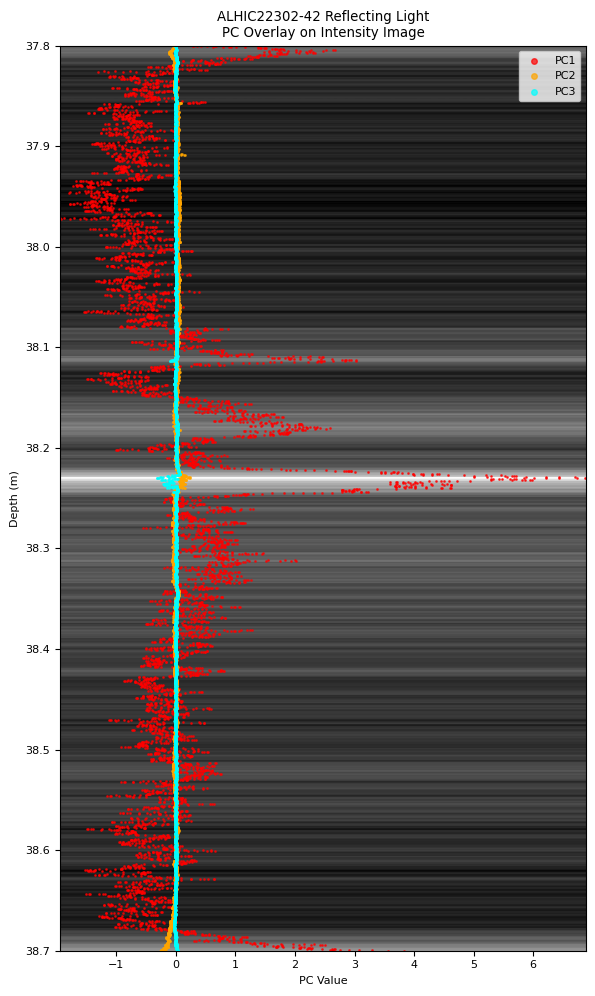

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path

# ---- Columns to plot ----
x_cols = ["PC1", "PC2", "PC3"]   # choose 2 or 3 here
colors = ["red", "orange", "cyan"]  # match order
labels = ["PC1", "PC2", "PC3"]

y_col = "Depth_cm"

csv_path = Path(str(pcaPath + "/" + csv_name))
img_path = Path(str(imgPath + "/" + img_name))

# --- Load data ---
df = pd.read_csv(csv_path).dropna(subset=[y_col] + x_cols)
df[y_col] = df[y_col] / 100  # cm → m

img = mpimg.imread(img_path)
H, W = img.shape[0], img.shape[1]

# --- Global axis bounds (important: shared across all plots) ---
x_min = min(df[col].min() for col in x_cols)
x_max = max(df[col].max() for col in x_cols)
y_min, y_max = float(df[y_col].min()), float(df[y_col].max())

def linmap(v, a0, a1, b0, b1):
    return b0 + (np.asarray(v) - a0) * (b1 - b0) / (a1 - a0 + 1e-12)

# Map depth → pixel space ONCE
y_px = linmap(df[y_col], y_min, y_max, 0, H)

# --- Plot ---
fig, ax = plt.subplots(figsize=(6, 10))

# Keep image dimensions fixed via extent
ax.imshow(
    img,
    extent=[x_min, x_max, H, 0],
    aspect="auto",
    interpolation="nearest",
    zorder=1
)

# ---- Overlay multiple scatter plots ----
for col, c, label in zip(x_cols, colors, labels):
    x_px = df[col]  # stays in data space (aligned via extent)
    ax.scatter(
        x_px,
        y_px,
        s=1,
        c=c,
        alpha=0.7,
        zorder=2,
        label=label
    )

# --- Y-axis ticks in real depth units ---
n_ticks = 10
pixel_ticks = np.linspace(0, H, n_ticks)
depth_labels = np.linspace(y_min, y_max, n_ticks)

ax.set_yticks(pixel_ticks)
ax.set_yticklabels([f"{d:.1f}" for d in depth_labels])

# --- Labels ---
ax.set_xlabel("PC Value")
ax.set_ylabel("Depth (m)")
ax.set_title("ALHIC22302-42 Reflecting Light\nPC Overlay on Intensity Image")

plt.tight_layout()
plt.legend(markerscale=4)

out_path = Path(outputPath) / "HSIUM-17_PCOverlay.png"
# fig.savefig(out_path, dpi=300, bbox_inches="tight")

plt.show()

In [21]:
# if inpainted_img.ndim != 3:
#         raise ValueError("Expected image with shape (height, width, channels)")

# removed = list(range(0, 10)) + list(range(211, 224))

# H, W, C = inpainted_img.shape
# # Use float64 for stable reductions
# imgf = inpainted_img.astype(np.float64, copy=False)

# # Row-wise reductions over width and channels -> shape (H,)
# row_sums  = np.sum(imgf, axis=1)        # total per row

# # heights = [274,  396,  495,  711, 1000, 1057, 1198, 1261, 1375, 1507, 1562, 1627, 1716, 1774,
# #  1863, 1943, 2095, 2182, 2469, 2646, 2702, 2872, 2997, 3106, 3177, 3243, 3327, 3401,
# #  3561, 3697, 3747, 3904, 4026, 4178, 4296, 4353, 4467, 4593, 4681, 4994, 5061, 5132,
# #  5198, 5309]          # example indices, adjust as needed
# heights = [226 , 345, 446, 663, 1008, 1148, 1211, 1264, 1454, 1511, 1577, 1662, 1859, 2028, 2418,
#            2653, 2824, 2946, 3122, 3199, 3276, 3349, 3511, 3604, 3697, 3854, 3976, 4130,
#            4302, 4417, 4630, 4747, 4944, 5011, 5083, 5154, 5212, 5290, 5350]
# peak_spectra = row_sums[heights, :]      # shape: (Peaks, C)


# # --- Plot spectra for each height ---
# plt.figure(figsize=(8, 8))
# for i, h in enumerate(heights):
#     h=h-2
#     plt.plot(np.arange(imgf.shape[2]), peak_spectra[i], label=f"Height {h}")

# plt.xlabel("Spectral Channel")
# plt.ylabel("Cumulative Intensity (over width)")
# plt.title("Spectral Profiles at Selected Heights")
# plt.legend()
# plt.tight_layout()
# outputPath = '/data/icecores/Output/Figures'
# # out_path = f"{outputPath}/HSIUM-104_CumulativeIntensityPeakProfiles.png"
# # plt.savefig(out_path, dpi=300, bbox_inches="tight")
# plt.show()

In [22]:
# peak_avg_spectra = np.mean(peak_spectra, axis=0)
# peak_std_dev = np.std(peak_spectra, axis=0)

# plt.figure(figsize=(8, 8))
# plt.plot(peak_avg_spectra, label=f'Avg Peak')
# plt.plot(peak_avg_spectra + peak_std_dev, color='green', linestyle='dashed', label=f'+1 Std Dev')
# plt.plot(peak_avg_spectra - peak_std_dev, color='green', linestyle='dashed', label=f'-1 Std Dev')
# plt.xlabel("Spectral Channel")
# plt.ylabel("Cumulative Intensity")
# plt.title("ALHIC2302-29\nSpectral Average of Peaks")
# plt.legend()
# plt.tight_layout()
# outputPath = '/data/icecores/Output/Figures'
# # out_path = f"{outputPath}/HSIUM-104_AvgPeakIntensity.png"
# # plt.savefig(out_path, dpi=300, bbox_inches="tight")
# plt.show()

In [23]:
# residual_peak_spectra = peak_spectra - peak_avg_spectra

# plt.figure(figsize=(8, 8))

# for i, h in enumerate(heights):
#     h = h - 2
#     plt.plot(np.arange(imgf.shape[2]), residual_peak_spectra[i], label=f"Height {h}")

# plt.axhline(0, color='black', linestyle='dashed', linewidth=1)  # important reference line

# plt.xlabel("Spectral Channel")
# plt.ylabel("Deviation from Mean Intensity")
# plt.title("Residual Spectral Profiles (Peak - Mean Peak)")
# plt.legend(loc="upper center", bbox_to_anchor=(.5, -0.02), ncols=4)
# plt.tight_layout()

# plt.show()

In [24]:
# if inpainted_img.ndim != 3:
#         raise ValueError("Expected image with shape (height, width, channels)")

# H, W, C = inpainted_img.shape
# # Use float64 for stable reductions
# imgf = inpainted_img.astype(np.float64, copy=False)

# # Row-wise reductions over width and channels -> shape (H,)
# row_sums  = np.sum(imgf, axis=1)        # total per row

# # heights = [57, 803,  933, 1102, 1166, 1221, 1288, 1536, 1601,
# #  1884, 1998, 2244, 2307, 2416, 2516, 2571, 2787, 2851, 2926, 2976, 3044, 3151, 3231,
# #  3281, 3450, 3525, 3611, 3873, 3928, 4079, 4229, 4408, 4548, 4706, 4894, 4954, 5094,
# #  5379]          # example indices, adjust as needed
# heights = [82, 251, 313, 382, 551, 622, 848, 988, 1052, 1117, 1173, 1486, 1551, 1944,
#            2092, 2257, 2366, 2466, 2519, 2628, 2737, 2877, 2979, 3078, 3231, 3401, 3474, 3563,
#            3625, 3815, 3877, 4023, 4073, 4179, 4270, 4358, 4498, 4577, 4656, 4837, 4905, 4963, 5043, 5329]
# spectra = row_sums[heights, :]      # shape: (3, C)


# # --- Plot spectra for each height ---
# plt.figure(figsize=(8, 8))
# for i, h in enumerate(heights):
#     h=h-2
#     plt.plot(np.arange(imgf.shape[2]), spectra[i], label=f"Height {h}")

# plt.xlabel("Spectral Channel")
# plt.ylabel("Cumulative Intensity (over width)")
# plt.title("Spectral Profiles at Selected Heights")
# plt.legend()
# plt.tight_layout()
# outputPath = '/data/icecores/Output/Figures'
# out_path = f"{outputPath}/HSIUM-104_CumulativeIntensityValleyProfiles.png"
# # plt.savefig(out_path, dpi=300, bbox_inches="tight")
# plt.show()

In [25]:
# Compute mean and std dev for valleys
# val_avg_spectra = np.mean(spectra, axis=0)
# val_std_dev = np.std(spectra, axis=0)
# val_upper = val_avg_spectra + val_std_dev
# val_lower = val_avg_spectra - val_std_dev

# residual_spectra = spectra - val_avg_spectra

# plt.figure(figsize=(8, 8))

# for i, h in enumerate(heights):
#     h = h - 2
#     plt.plot(np.arange(imgf.shape[2]), residual_spectra[i], label=f"Height {h}")

# plt.axhline(0, color='black', linestyle='dashed', linewidth=1)  # important reference line

# plt.xlabel("Spectral Channel")
# plt.ylabel("Deviation from Mean Intensity")
# plt.title("Residual Spectral Profiles (Val - Mean Val)")
# plt.legend(loc="upper center", bbox_to_anchor=(.5, -0.02), ncols=4)
# plt.tight_layout()

# plt.show()

In [26]:
# import numpy as np

# # full range
# n_bands = 224
# start, end = 0.4, 1.0
# band_width = (end - start) / n_bands
# wavelengths = np.array([start + i * band_width for i in range(n_bands)])

# # remove edges
# removed = list(range(0, 10)) + list(range(211, 224))
# kept = np.delete(wavelengths, removed)
# peak_spectra = np.delete(peak_spectra, removed, axis=1)
# spectra = np.delete(spectra, removed, axis=1)

# # now kept gives µm per remaining channel
# print(kept[:5], kept[-5:])

In [27]:
# peak_avg_spectra = np.mean(peak_spectra, axis=0)
# residual_peak_spectra = peak_spectra - peak_avg_spectra

# plt.figure(figsize=(8, 8))

# for i, h in enumerate(heights):
#     h = h - 2
#     plt.plot(np.arange(kept), residual_peak_spectra, label=f"Height {h}")

# plt.axhline(0, color='black', linestyle='dashed', linewidth=1)  # important reference line

# plt.xlabel("Spectral Channel")
# plt.ylabel("Deviation from Mean Intensity")
# plt.title("Residual Spectral Profiles (Peak - Mean Peak)")
# plt.legend(loc="upper center", bbox_to_anchor=(.5, -0.02), ncols=4)
# plt.tight_layout()

# plt.show()

In [28]:
# val_avg_spectra = np.mean(spectra, axis=0)
# residual_spectra = spectra - val_avg_spectra

# plt.figure(figsize=(8, 8))

# for i, h in enumerate(heights):
#     h = h - 2
#     plt.plot(kept, residual_spectra[i], label=f"Height {h}")

# plt.axhline(0, color='black', linestyle='dashed', linewidth=1)  # important reference line

# plt.xlabel("Spectral Channel")
# plt.ylabel("Deviation from Mean Intensity")
# plt.title("Residual Spectral Profiles (Val - Mean Val)")
# plt.legend(loc="upper center", bbox_to_anchor=(.5, -0.02), ncols=4)
# plt.tight_layout()

# plt.show()

In [29]:
# import matplotlib.pyplot as plt
# import numpy as np

# C = peak_avg_spectra.shape[0]
# x = np.arange(C)
# print("x = ", x)

# x_um = kept

# # Compute mean and std dev for peaks
# peak_avg_spectra = np.mean(peak_spectra, axis=0)
# peak_std_dev = np.std(peak_spectra, axis=0)
# peak_upper = peak_avg_spectra + peak_std_dev
# peak_lower = peak_avg_spectra - peak_std_dev

# # Compute mean and std dev for valleys
# val_avg_spectra = np.mean(spectra, axis=0)
# val_std_dev = np.std(spectra, axis=0)
# val_upper = val_avg_spectra + val_std_dev
# val_lower = val_avg_spectra - val_std_dev

# # Create two stacked plots with shared x-axis
# fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

# # --- Plot Peaks ---
# ax1.plot(x_um, peak_avg_spectra, linewidth=2, label='Avg High Intensity Layer', color='red')
# ax1.plot(x_um, peak_upper, color='C7', linestyle='dashed', label='+1 σ')
# ax1.plot(x_um, peak_lower, color='C7', linestyle='dashed', label='-1 σ')
# ax1.fill_between(x_um, peak_lower, peak_upper, facecolor='C7', alpha=0.15, label='1 σ range')
# ax1.set_ylabel("Cumulative Intensity", fontsize=10)
# ax1.set_title("Spectral Averages of High Intensity Layers", fontsize=12)
# ax1.legend()

# # --- Plot Valleys ---
# ax2.plot(x_um, val_avg_spectra, linewidth=2, color='C0', label='Avg Low Intensity Layer')
# ax2.plot(x_um, val_upper, color='green', linestyle='dashed', label='+1 σ')
# ax2.plot(x_um, val_lower, color='green', linestyle='dashed', label='-1 σ')
# ax2.fill_between(x_um, val_lower, val_upper, facecolor='green', alpha=0.15, label='1 σ range')
# ax2.set_xlabel("Wavelength (µm)", fontsize=10)
# ax2.set_ylabel("Cumulative Intensity", fontsize=10)
# ax2.set_title("Spectral Averages of Low Intensity Layers", fontsize=12)
# ax2.legend()
# #plt.suptitle("ALHIC2302-29", fontsize=14, fontweight='bold')
# plt.tight_layout()

# outputPath = '/data/icecores/Output/Figures'
# out_path = f"{outputPath}/ALHIC2302-29_AvgPeakValleyIntensity_split.png"
# # plt.savefig(out_path, dpi=300, bbox_inches="tight")
# plt.show()

In [30]:
# peak_avg_spectra = np.mean(peak_spectra, axis=0)
# peak_residuals = peak_spectra - peak_avg_spectra

# val_avg_spectra = np.mean(spectra, axis=0)
# val_residuals = spectra - val_avg_spectra

# fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

# # --- Peaks residuals ---
# for i in range(peak_residuals.shape[0]):
#     ax1.plot(x_um, peak_residuals[i], alpha=0.7)

# ax1.axhline(0, color='black', linestyle='dashed', linewidth=1)

# ax1.set_ylabel("Deviation from Mean", fontsize=10)
# ax1.set_title("Residual Spectra (High Intensity Layers)", fontsize=12)


# # --- Valleys residuals ---
# for i in range(val_residuals.shape[0]):
#     ax2.plot(x_um, val_residuals[i], alpha=0.7)

# ax2.axhline(0, color='black', linestyle='dashed', linewidth=1)

# ax2.set_xlabel("Wavelength (µm)", fontsize=10)
# ax2.set_ylabel("Deviation from Mean", fontsize=10)
# ax2.set_title("Residual Spectra (Low Intensity Layers)", fontsize=12)

# plt.tight_layout()
# outputPath = '/data/icecores/Output/Figures'
# out_path = f"{outputPath}/ALHIC2302-29_ResidualIntensity.png"
# plt.savefig(out_path, dpi=300, bbox_inches="tight")
# plt.show()

In [31]:
# plt.figure(figsize=(6, 6))

# plt.scatter(peak_avg_spectra, val_avg_spectra, alpha=0.7)
# plt.xlabel("Peak Intensity")
# plt.ylabel("Valley Intensity")
# plt.title(f"Peak vs Valley Correlation")

# # 1:1 reference line
# min_val = min(peak_avg_spectra.min(), val_avg_spectra.min())
# max_val = max(peak_avg_spectra.max(), val_avg_spectra.max())
# plt.plot([min_val, max_val], [min_val, max_val], linestyle='--')

# plt.tight_layout()
# plt.show()

In [32]:
# ndi = (peak_avg_spectra - val_avg_spectra) / (peak_avg_spectra + val_avg_spectra)

# plt.figure(figsize=(8, 8))
# # --- Plot NDI ---
# plt.plot(x_um, ndi, color='purple', linewidth=2, label='NDI (Peak vs Valley)')
# #plt.axhline(0, color='black', linestyle='--', linewidth=1)
# # plt.set_xlabel("Wavelength (µm)", fontsize=10)
# # plt.set_ylabel("NDI", fontsize=10)
# # plt.set_title("Normalized Difference Index (Peak vs Valley)", fontsize=12)
# plt.legend()